In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT / "tests"))
TABLES, FIGS, PROC = ROOT / "reports/tables", ROOT / "reports/figures", ROOT / "data/processed"
from olpred.viz import style; style.apply()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

def show(name, width=820):
    display(Image(filename=str(FIGS / name), width=width))

def table(name, **kw):
    return pd.read_csv(TABLES / name, **kw)


# 02 — Feature engineering and leakage control
Every feature of a match is built from matches **strictly before** it. Details: `docs/features.md`.

In [2]:
f = pd.read_parquet(PROC / "features.parquet")
from olpred.features.columns import curated_cols, legacy_cols
from olpred.interpret import families
print(f.shape, "| candidate columns:", len(legacy_cols(f)), "| curated (final):", len(curated_cols(f)))
pd.Series({k: len(v) for k, v in families(curated_cols(f)).items()}, name="columns").to_frame()

(29239, 124) | candidate columns: 106 | curated (final): 100


,columns
Elo rating,4
Recent form (3/5/10 matches),30
Shots (on target / against),18
xG proxy,18
Venue form (home/away),9
League table,9
Fatigue / schedule,6
Squad market value,6


### The Elo rating is informative (and honest)
Home-win rate by quintile of the pre-match Elo expectation:

In [3]:
q = pd.qcut(f.elo_exp_home, 5)
g = f.groupby(q, observed=True).apply(lambda d: pd.Series({"Elo expectation": d.elo_exp_home.mean(),
        "home win": (d.y==2).mean(), "draw": (d.y==1).mean(), "away win": (d.y==0).mean()}), include_groups=False)
g.round(3)

,Elo expectation,home win,draw,away win
elo_exp_home,,,,
"(0.0562, 0.414]",0.300,0.217,0.234,0.549
"(0.414, 0.542]",0.483,0.350,0.293,0.357
"(0.542, 0.639]",0.590,0.450,0.279,0.271
"(0.639, 0.749]",0.691,0.515,0.274,0.210
"(0.749, 0.978]",0.830,0.703,0.181,0.115


### Leakage test (perturbation)
All results from a cutoff onward are replaced by random values and the whole pipeline is re-run: features of every earlier match — and of matches on the cutoff day, which tests independence from their own result — must be unchanged.

In [4]:
from test_leakage import synthetic_matches, perturb_from, TARGET_COLS
from olpred.features.build import build_features
m = synthetic_matches()
cutoff = sorted(m.date.unique())[25]
a = build_features(m, xg_train_end=2010); b = build_features(perturb_from(m, cutoff), xg_train_end=2010)
cols = [c for c in a.columns if c not in TARGET_COLS | {"match_id"}]
past = a.date <= cutoff
diff = (a.loc[past, cols].select_dtypes("number").reset_index(drop=True)
        - b.loc[b.date <= cutoff, cols].select_dtypes("number").reset_index(drop=True)).abs().max().max()
future = (a.loc[~past, cols].select_dtypes("number").reset_index(drop=True)
          - b.loc[~(b.date <= cutoff), cols].select_dtypes("number").reset_index(drop=True)).abs().max().max()
print(f"max |difference| in features up to the cutoff: {diff}   (after the cutoff: {future:.3f}, as expected)")

max |difference| in features up to the cutoff: 0.0   (after the cutoff: 185.071, as expected)


### The 'xG proxy' is just shots on target
Fitted `goals = a·SOT + b·(shots off target)` with non-negative coefficients:

In [5]:
from olpred.features.form import to_long
from olpred.features.xg_proxy import XGProxy
mm = pd.read_parquet(PROC / "matches.parquet"); l = to_long(mm); tr = l[l.season <= 2019]
print(XGProxy().fit(tr.shots, tr.sot, tr.gf).coefs)

{'per_shot_on_target': 0.28676993868021095, 'per_shot_off_target': 0.0}


### A variable removed as a problematic proxy
`n_prior` counts matches seen so far: a calendar clock, not team quality.

In [6]:
f.groupby("season")["h_n_prior"].mean().round(0).astype(int).to_frame("mean n_prior of home teams").T

season,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
mean n_prior of home teams,18,50,79,107,133,161,185,213,238,267,293,318,337,365,400,430,431


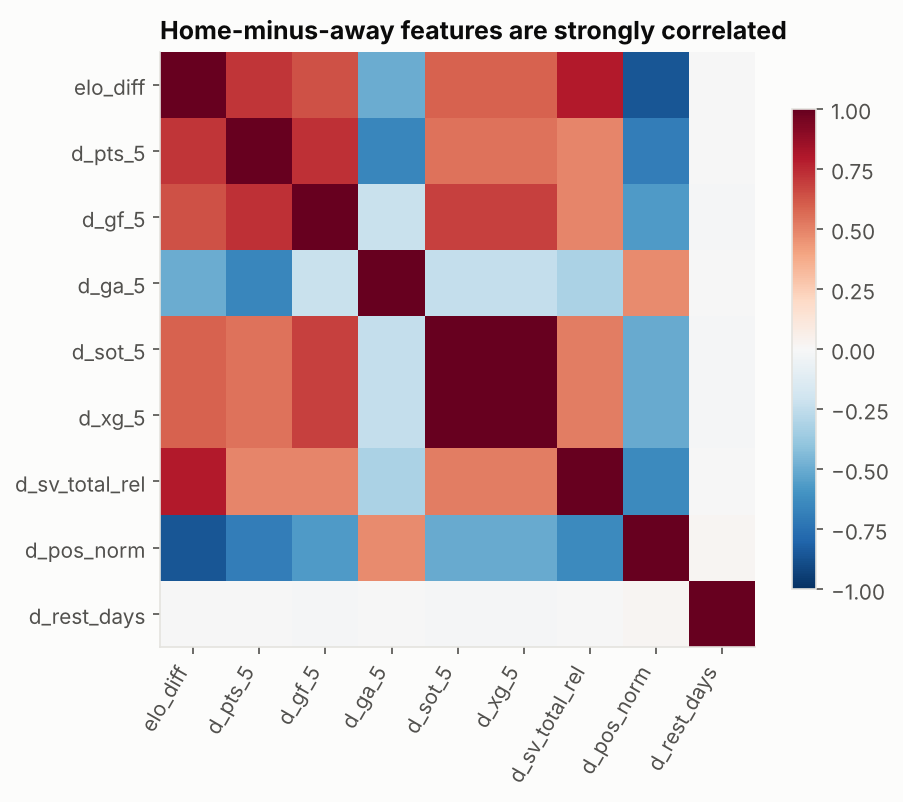

In [7]:
cols = ["elo_diff", "d_pts_5", "d_gf_5", "d_ga_5", "d_sot_5", "d_xg_5", "d_sv_total_rel", "d_pos_norm", "d_rest_days"]
c = f[cols].corr()
fig, ax = plt.subplots(figsize=(6.4, 5.2)); im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(cols)), cols, rotation=60, ha="right"); ax.set_yticks(range(len(cols)), cols)
plt.colorbar(im, shrink=0.8); ax.set_title("Home-minus-away features are strongly correlated"); plt.show()